###Airport Case Study

##Step 1 Data Preparation:


###1a) Import necessary packages

In [ ]:
#import pandas, numpy, matplotlib, seaborn and geopandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

###1b) Import and read necessary files for project

In [ ]:
#import main airport database file and rename to airport_data
airport_data = pd.read_csv('GlobalAirportDatabase.csv')

In [ ]:
#import TSA claims file
tsa_claims = pd.read_csv('tsa_claims2.csv')

###Import and extract maps.zip file

In [ ]:
#import maps.zip, unzip file and load all shapefiles into states_map
from zipfile import ZipFile
import geopandas as gpd

file_name = 'maps.zip'
with ZipFile(file_name, 'r') as zip_ref:
    zip_ref.extractall()
    # Print details of the extracted files
    for file in zip_ref.infolist():
        print(file.filename, file.compress_type, file.compress_size, file.file_size)

# Load the shapefile into states_map
states_map = gpd.read_file('maps/states.shp')

maps/ 0 0 0
__MACOSX/._maps 8 135 212
maps/states.dbf 8 878 2846
__MACOSX/maps/._states.dbf 8 135 212
maps/states.sbx 8 81 148
__MACOSX/maps/._states.sbx 8 135 212
maps/states.shx 8 369 508
__MACOSX/maps/._states.shx 8 135 212
maps/states.shp 8 159324 222392
__MACOSX/maps/._states.shp 8 135 212
maps/states.shp.xml 8 1060 2842
__MACOSX/maps/._states.shp.xml 8 135 212
maps/states.sbn 8 420 596
__MACOSX/maps/._states.sbn 8 135 212
maps/states.prj 8 135 167
__MACOSX/maps/._states.prj 8 135 212


###1c) Cleaning Files: main data file (airport_data)

In [ ]:
#get datatype info on airport_data
airport_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9300 entries, 0 to 9299
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ICAOCode                 9300 non-null   object 
 1   IATACode                 3562 non-null   object 
 2   AirportName              4195 non-null   object 
 3   City                     9300 non-null   object 
 4   Country                  9300 non-null   object 
 5   LatitudeDegrees          9300 non-null   int64  
 6   LatitudeMinutes          9300 non-null   int64  
 7   LatitudeSeconds          9300 non-null   int64  
 8   LatitudeDir              9300 non-null   object 
 9   LongitudeDegrees         9300 non-null   int64  
 10  LongitudeMinutes         9300 non-null   int64  
 11  LongitudeSeconds         9300 non-null   int64  
 12  LongitudeDirection       9300 non-null   object 
 13  Altitude                 9300 non-null   int64  
 14  LatitudeDecimalDegrees  

In [ ]:
#obtain head data on airport_data
airport_data.head()

,ICAOCode,IATACode,AirportName,City,Country,LatitudeDegrees,LatitudeMinutes,LatitudeSeconds,LatitudeDir,LongitudeDegrees,LongitudeMinutes,LongitudeSeconds,LongitudeDirection,Altitude,LatitudeDecimalDegrees,LongitudeDecimalDegrees
0,AYGA,GKA,GOROKA,GOROKA,PAPUA NEW GUINEA,6,4,54,S,145,23,30,E,1610,-6.082,145.392
1,AYLA,LAE,NaN,LAE,PAPUA NEW GUINEA,0,0,0,U,0,0,0,U,0,0.000,0.000
2,AYMD,MAG,MADANG,MADANG,PAPUA NEW GUINEA,5,12,25,S,145,47,19,E,7,-5.207,145.789
3,AYMH,HGU,MOUNT HAGEN,MOUNT HAGEN,PAPUA NEW GUINEA,5,49,34,S,144,17,46,E,1643,-5.826,144.296
4,AYNZ,LAE,NADZAB,NADZAB,PAPUA NEW GUINEA,6,34,11,S,146,43,34,E,73,-6.570,146.726


In [ ]:
# Obtain missing values in airport_data
missing_values = airport_data.isnull().sum()
print(missing_values)



ICAOCode                      0
IATACode                   5738
AirportName                5105
City                          0
Country                       0
LatitudeDegrees               0
LatitudeMinutes               0
LatitudeSeconds               0
LatitudeDir                   0
LongitudeDegrees              0
LongitudeMinutes              0
LongitudeSeconds              0
LongitudeDirection            0
Altitude                      0
LatitudeDecimalDegrees        0
LongitudeDecimalDegrees       0
dtype: int64


In [ ]:
# Verified no instances contain missing values for all features
null_rows_count = airport_data.isnull().all(axis=1).sum()
print(f"Number of instances with null values across all features in airport_data: {null_rows_count}")

Number of instances with null values across all features in airport_data: 0


In [ ]:
# Show the number of unique values for each feature in airport_data
for col in airport_data.columns:
    print(f"{col}: {airport_data[col].nunique()} unique values")

ICAOCode: 9300 unique values
IATACode: 3511 unique values
AirportName: 4160 unique values
City: 8609 unique values
Country: 229 unique values
LatitudeDegrees: 80 unique values
LatitudeMinutes: 60 unique values
LatitudeSeconds: 60 unique values
LatitudeDir: 3 unique values
LongitudeDegrees: 180 unique values
LongitudeMinutes: 60 unique values
LongitudeSeconds: 60 unique values
LongitudeDirection: 3 unique values
Altitude: 1044 unique values
LatitudeDecimalDegrees: 4077 unique values
LongitudeDecimalDegrees: 4144 unique values


In [ ]:
#try to answer why there are 3 unique values in feature LatitudeDir
airport_data['LatitudeDir'].value_counts()


,count
LatitudeDir,
U,5112
N,3317
S,871


In [ ]:
#try to asnwer why there are 3 unique values in feature LongitudeDirection
airport_data['LongitudeDirection'].value_counts()

,count
LongitudeDirection,
U,5112
E,2389
W,1799


###Latitude and Longitude contains "U" for unknown, attempting to use corresponding latitude coordinates to change to North, South, East or West (N/S/E/W respectively)

In [ ]:
# First, convert the LatitudeDir column to the category data type
if airport_data['LatitudeDir'].dtype != 'category':
    airport_data['LatitudeDir'] = airport_data['LatitudeDir'].astype('category')

# Attempting to find U instances and use long/latitude coordinates to determine if it can be changed to North or South
if 'N' not in airport_data['LatitudeDir'].cat.categories:
    airport_data['LatitudeDir'] = airport_data['LatitudeDir'].cat.add_categories(['N'])
if 'S' not in airport_data['LatitudeDir'].cat.categories:
    airport_data['LatitudeDir'] = airport_data['LatitudeDir'].cat.add_categories(['S'])

# Find the index of rows where LatitudeDir is 'U'
unknown_lat_mask = (airport_data['LatitudeDir'] == 'U')

# Impute 'N' for positive or zero values of LatitudeDecimalDegrees, and 'S' for negative values
airport_data.loc[unknown_lat_mask & (airport_data['LatitudeDecimalDegrees'] >= 0), 'LatitudeDir'] = 'N'
airport_data.loc[unknown_lat_mask & (airport_data['LatitudeDecimalDegrees'] < 0), 'LatitudeDir'] = 'S'

# Remove 'U' from categories if it is no longer needed
airport_data['LatitudeDir'] = airport_data['LatitudeDir'].cat.remove_unused_categories()

# Show updated value counts
print("Updated LatitudeDir Value Counts:")
print(airport_data['LatitudeDir'].value_counts())

Updated LatitudeDir Value Counts:
LatitudeDir
N    8429
S     871
Name: count, dtype: int64


In [ ]:
# First, convert the LongitudeDirection column to the category data type
if airport_data['LongitudeDirection'].dtype != 'category':
    airport_data['LongitudeDirection'] = airport_data['LongitudeDirection'].astype('category')

# Since LongitudeDirection is a categorical type, temporarily add categories if they aren't present
if 'E' not in airport_data['LongitudeDirection'].cat.categories:
    airport_data['LongitudeDirection'] = airport_data['LongitudeDirection'].cat.add_categories(['E'])
if 'W' not in airport_data['LongitudeDirection'].cat.categories:
    airport_data['LongitudeDirection'] = airport_data['LongitudeDirection'].cat.add_categories(['W'])

# Find the index of rows where LongitudeDirection is 'U'
unknown_long_mask = (airport_data['LongitudeDirection'] == 'U')

# Impute 'E' for positive or zero values of LongitudeDecimalDegrees, and 'W' for negative values
airport_data.loc[unknown_long_mask & (airport_data['LongitudeDecimalDegrees'] >= 0), 'LongitudeDirection'] = 'E'
airport_data.loc[unknown_long_mask & (airport_data['LongitudeDecimalDegrees'] < 0), 'LongitudeDirection'] = 'W'

# Remove 'U' from categories if it is no longer used
airport_data['LongitudeDirection'] = airport_data['LongitudeDirection'].cat.remove_unused_categories()

# Show updated value counts
print("Updated LongitudeDirection Value Counts:")
print(airport_data['LongitudeDirection'].value_counts())

Updated LongitudeDirection Value Counts:
LongitudeDirection
E    7501
W    1799
Name: count, dtype: int64


###Verified below that all unknown direction instances in longitudeDir and latitudeDir have been changed to proper N/S/E/W labels


In [ ]:
#Verified unknown latitudes were change to specific N/S direction labels
airport_data['LatitudeDir'].value_counts()

,count
LatitudeDir,
N,8429
S,871


In [ ]:
airport_data['LongitudeDirection'].value_counts()

,count
LongitudeDirection,
E,7501
W,1799


###Next, matched airport_data with tsa_claims in an attempt to backfill in airport names and IATA codes for each dataset.

In [ ]:
#Standardize and build a reliable lookup dictionary of IATA Code -> Airport Name
#We gather mappings from both datasets to ensure a comprehensive reference dictionary
lookup_dict = {}

#Extract valid mappings from airport_data
valid_airport_ref = airport_data[airport_data['IATACode'].notna() & (airport_data['IATACode'] != '')]
for _, row in valid_airport_ref.iterrows():
    iata = str(row['IATACode']).strip().upper()
    name = str(row['AirportName']).strip()
    if iata and name and "Area Airport" not in name:  # Prefer authentic original names over fallback generated ones
        lookup_dict[iata] = name

#Extract valid mappings from tsa_claims
valid_tsa_ref = tsa_claims[
    (tsa_claims['Airport Code'].notna()) &
    (tsa_claims['Airport Code'] != 'Unspecified') &
    (tsa_claims['Airport Code'] != '-') &
    (tsa_claims['Airport Name'].notna()) &
    (tsa_claims['Airport Name'] != 'Unspecified') &
    (tsa_claims['Airport Name'] != '-')
]
for _, row in valid_tsa_ref.iterrows():
    iata = str(row['Airport Code']).strip().upper()
    name = str(row['Airport Name']).strip()
    if iata and name:
        # Let TSA Claims name serve as an additional high-quality match if not already mapped
        if iata not in lookup_dict:
            lookup_dict[iata] = name

#Reverse lookup dictionary for Name -> IATA Code mapping
reverse_lookup = {v.lower(): k for k, v in lookup_dict.items()}

#Backfill missing IATACode in airport_data using the Name lookup
missing_iata_mask = airport_data['IATACode'].isna() | (airport_data['IATACode'] == 'Unspecified')
for idx, row in airport_data[missing_iata_mask].iterrows():
    name = str(row['AirportName']).strip().lower()
    if name in reverse_lookup:
        airport_data.at[idx, 'IATACode'] = reverse_lookup[name]

# Backfill missing/Unspecified values in tsa_claims dataset
# Backfill Airport Names using the Airport Code
mask_missing_tsa_name = (tsa_claims['Airport Name'] == 'Unspecified') | (tsa_claims['Airport Name'].isna())
for idx, row in tsa_claims[mask_missing_tsa_name].iterrows():
    code = str(row['Airport Code']).strip().upper()
    if code in lookup_dict:
        tsa_claims.at[idx, 'Airport Name'] = lookup_dict[code]

#Backfill Airport Codes using the Airport Name
mask_missing_tsa_code = (tsa_claims['Airport Code'] == 'Unspecified') | (tsa_claims['Airport Code'].isna())
for idx, row in tsa_claims[mask_missing_tsa_code].iterrows():
    name = str(row['Airport Name']).strip().lower()
    if name in reverse_lookup:
        tsa_claims.at[idx, 'Airport Code'] = reverse_lookup[name]

print("Backfilling complete!")
print(f"Total mapped reference airport entries: {len(lookup_dict)}")
print(f"Remaining null/unspecified IATA codes in airport_data: {airport_data['IATACode'].isna().sum()}")


Backfilling complete!
Total mapped reference airport entries: 3707
Remaining null/unspecified IATA codes in airport_data: 1228


In [ ]:
# Verify remaining missing values in airport_data after synchronization
missing_after_backfill = airport_data.isnull().sum()
print("Missing values per feature in airport_data:")
print(missing_after_backfill)

Missing values per feature in airport_data:
ICAOCode                      0
IATACode                   1228
AirportName                5105
City                          0
Country                       0
LatitudeDegrees               0
LatitudeMinutes               0
LatitudeSeconds               0
LatitudeDir                   0
LongitudeDegrees              0
LongitudeMinutes              0
LongitudeSeconds              0
LongitudeDirection            0
Altitude                      0
LatitudeDecimalDegrees        0
LongitudeDecimalDegrees       0
dtype: int64


###Verified only IATACodes have remaining missing values. According to the following article (https://pilotinstitute.com/airport-codes-explained/) some airports may not have a specific IATA Code assigned due to its size and location.


###1d) Cleaning Files: tsa_claims file

In [ ]:
#obtain info for tsa_claims file
tsa_claims.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145688 entries, 0 to 145687
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Claim Number   145688 non-null  object
 1   Date Received  145427 non-null  object
 2   Incident Date  143507 non-null  object
 3   Airport Code   145688 non-null  object
 4   Airport Name   145688 non-null  object
 5   Airline Name   111316 non-null  object
 6   Claim Type     137777 non-null  object
 7   Claim Site     144950 non-null  object
 8   Item           141724 non-null  object
 9   Claim Amount   141647 non-null  object
 10  Status         145685 non-null  object
 11  Close Amount   135315 non-null  object
 12  Disposition    131359 non-null  object
dtypes: object(13)
memory usage: 14.4+ MB


In [ ]:
# Show the number of unique values for each feature in tsa_claims
for col in tsa_claims.columns:
    print(f"{col}: {tsa_claims[col].nunique()} unique values")

Claim Number: 145687 unique values
Date Received: 2193 unique values
Incident Date: 4853 unique values
Airport Code: 430 unique values
Airport Name: 438 unique values
Airline Name: 221 unique values
Claim Type: 7 unique values
Claim Site: 6 unique values
Item: 3450 unique values
Claim Amount: 33120 unique values
Status: 15 unique values
Close Amount: 17162 unique values
Disposition: 3 unique values


###Determine feature layout of tsa_claims file

In [ ]:
#view feature layout in tsa_claims file
tsa_claims.head()

,Claim Number,Date Received,Incident Date,Airport Code,Airport Name,Airline Name,Claim Type,Claim Site,Item,Claim Amount,Status,Close Amount,Disposition
0,0909802M,4-Jan-02,12/12/2002 0:00,EWR,Newark International Airport,Continental Airlines,Property Damage,Checkpoint,Other,$350.00,Approved,$350.00,Approve in Full
1,0202417M,2-Feb-02,1/16/2004 0:00,SEA,Seattle-Tacoma International,NaN,Property Damage,Checked Baggage,Luggage (all types including footlockers),$100.00,Settled,$50.00,Settle
2,0202445M,4-Feb-02,11/26/2003 0:00,STL,Lambert St. Louis International,American Airlines,Property Damage,Checked Baggage,Cell Phones,$278.88,Settled,$227.92,Settle
3,0909816M,7-Feb-02,1/6/2003 0:00,MIA,Miami International Airport,American Airlines,Property Damage,Checkpoint,Luggage (all types including footlockers),$50.00,Approved,$50.00,Approve in Full
4,2005032379513,18-Feb-02,2/5/2005 0:00,MCO,Orlando International Airport,Delta (Song),Property Damage,Checkpoint,Baby - Strollers; car seats; playpen; etc.,$84.79,Approved,$84.79,Approve in Full


###Two features contain dates that need to be changed to datetime datatypes, enter code below to change from object to datatime datatype.

In [ ]:
# Convert Date Received and Incident Date columns to datetime format
tsa_claims['Date Received'] = pd.to_datetime(tsa_claims['Date Received'], errors='coerce')
tsa_claims['Incident Date'] = pd.to_datetime(tsa_claims['Incident Date'], errors='coerce')

# Display the datatypes to verify the changes
print(tsa_claims[['Date Received', 'Incident Date']].dtypes)
print("\nSample dates after conversion:")
print(tsa_claims[['Date Received', 'Incident Date']].head())

Date Received    datetime64[ns]
Incident Date    datetime64[ns]
dtype: object

Sample dates after conversion:
  Date Received Incident Date
0    2002-01-04    2002-12-12
1    2002-02-02    2004-01-16
2    2002-02-04    2003-11-26
3    2002-02-07    2003-01-06
4    2002-02-18    2005-02-05


/tmp/ipykernel_2040/3214338348.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  tsa_claims['Date Received'] = pd.to_datetime(tsa_claims['Date Received'], errors='coerce')


###Determine missing values in tsa_claim file and effect on the total instances in those features

In [ ]:
# Calculate null counts and percentages for each feature in tsa_claims
tsa_missing_counts = tsa_claims.isnull().sum()
tsa_missing_percentages = (tsa_claims.isnull().sum() / len(tsa_claims)) * 100

# Combine into a DataFrame for a clean summary table
tsa_missing_df = pd.DataFrame({
    'Missing Count': tsa_missing_counts,
    'Percentage (%)': tsa_missing_percentages
})

print("Missing Value Analysis for tsa_claims:")
print(tsa_missing_df)

Missing Value Analysis for tsa_claims:
               Missing Count  Percentage (%)
Claim Number               0        0.000000
Date Received            261        0.179150
Incident Date           2345        1.609604
Airport Code               0        0.000000
Airport Name               0        0.000000
Airline Name           34372       23.592883
Claim Type              7911        5.430097
Claim Site               738        0.506562
Item                    3964        2.720883
Claim Amount            4041        2.773736
Status                     3        0.002059
Close Amount           10373        7.120010
Disposition            14329        9.835402


In [ ]:
# Verified no instances have null values across all features
null_rows = tsa_claims[tsa_claims.isnull().all(axis=1)]
print(f"Number of rows with null values across all features: {len(null_rows)}")

# Display a sample or indices of those rows if they exist
if len(null_rows) > 0:
    print("Row indices of completely null rows:")
    print(null_rows.index.tolist()[:10], "..." if len(null_rows) > 10 else "")

Number of rows with null values across all features: 0


###Since no missing values for an instance are listed across all of the features and are unable to be imputed due to the context of those features, change all missing features to "Unspecified" as to not skew any analysis downstream.  

In [ ]:
# Iterate through each column to fill missing values with 'Unspecified' label
for col in tsa_claims.columns:
    # If the column is categorical, add 'Unspecified' to the categories list first
    if hasattr(tsa_claims[col], 'cat'):
        if 'Unspecified' not in tsa_claims[col].cat.categories:
            tsa_claims[col] = tsa_claims[col].cat.add_categories(['Unspecified'])
        tsa_claims[col] = tsa_claims[col].fillna('Unspecified')
    else:
        tsa_claims[col] = tsa_claims[col].fillna('Unspecified')

# Verify that no missing values remain in the DataFrame
print("Remaining null counts in tsa_claims:")
print(tsa_claims.isnull().sum())

Remaining null counts in tsa_claims:
Claim Number     0
Date Received    0
Incident Date    0
Airport Code     0
Airport Name     0
Airline Name     0
Claim Type       0
Claim Site       0
Item             0
Claim Amount     0
Status           0
Close Amount     0
Disposition      0
dtype: int64


##Part 2 Data Analysis

###Question 1: What is the most common type of insurance claim?

In [ ]:
# Calculate and print the descending value counts of 'Claim Type' feature
claim_type_counts = tsa_claims['Claim Type'].value_counts(dropna=False)
print(claim_type_counts)

Claim Type
Passenger Property Loss    82927
Property Damage            52912
Unspecified                 7911
Personal Injury              856
Passenger Theft              465
Employee Loss (MPCECA)       452
Motor Vehicle                163
-                              2
Name: count, dtype: int64


###Due to value count list including another unspecified value, that of "-", changed the instances of that value to also be changed to "Unspecified" instance for analysis purposes.

In [ ]:
# Iterate throughout claim type feature to replace "-" with "Unspecified" label
if hasattr(tsa_claims['Claim Type'], 'cat'):
    if 'Unspecified' not in tsa_claims['Claim Type'].cat.categories:
        tsa_claims['Claim Type'] = tsa_claims['Claim Type'].cat.add_categories(['Unspecified'])

# Replace '-' with 'Unspecified' in the 'Claim Type' column
tsa_claims['Claim Type'] = tsa_claims['Claim Type'].replace('-', 'Unspecified')

# Remove '-' from the categorical options to clean up unused categories
if hasattr(tsa_claims['Claim Type'], 'cat') and '-' in tsa_claims['Claim Type'].cat.categories:
    tsa_claims['Claim Type'] = tsa_claims['Claim Type'].cat.remove_unused_categories()

# Print the updated value counts to verify change occured
print("Updated Claim Type Value Counts:")
print(tsa_claims['Claim Type'].value_counts(dropna=False))

Updated Claim Type Value Counts:
Claim Type
Passenger Property Loss    82927
Property Damage            52912
Unspecified                 7913
Personal Injury              856
Passenger Theft              465
Employee Loss (MPCECA)       452
Motor Vehicle                163
Name: count, dtype: int64



###Question 1: What is the most common type of insurance claim?

###To answer the question, we would need to identify and visualize the top 5 claims

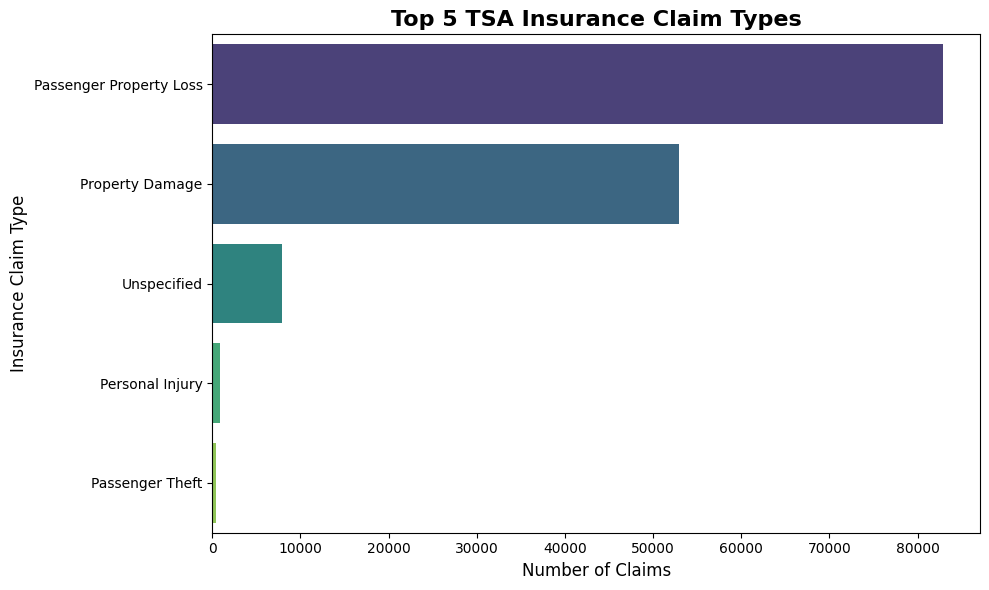

In [ ]:
# Calculate the top 5 claim types
top_5_claims = tsa_claims['Claim Type'].value_counts().head(5)

# Plot the bar graph
plt.figure(figsize=(10, 6))
sns.barplot(x=top_5_claims.values, y=top_5_claims.index, palette='viridis', hue=top_5_claims.index, legend=False)

# Add titles and labels
plt.title('Top 5 TSA Insurance Claim Types', fontsize=16, fontweight='bold')
plt.xlabel('Number of Claims', fontsize=12)
plt.ylabel('Insurance Claim Type', fontsize=12)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

###Due to visualization being tightly compacted at the lower end, change to logarithmic scale to visualize comparison more adequately.

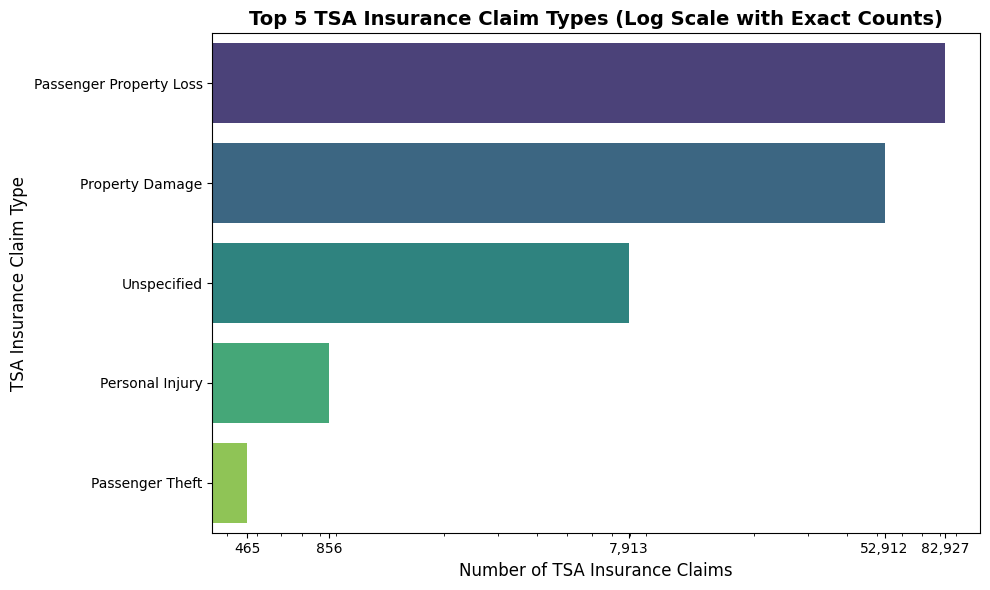

In [ ]:
import matplotlib.ticker as ticker

# Calculate the top 5 claim types
top_5_claims = tsa_claims['Claim Type'].value_counts().head(5)

# Plot the bar graph
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_5_claims.values, y=top_5_claims.index, palette='viridis', hue=top_5_claims.index, legend=False)

# Apply logarithmic scale to the x axis
plt.xscale('log')

# Set x-axis ticks exclusively for the exact count values of each claim type
exact_ticks = sorted(list(top_5_claims.values))
ax.set_xticks(exact_ticks)

# Format the x-axis ticks to display the exact integer values
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:,.0f}'.format(y)))

# Add titles and labels
plt.title('Top 5 TSA Insurance Claim Types (Log Scale with Exact Counts)', fontsize=14, fontweight='bold')
plt.xlabel('Number of TSA Insurance Claims', fontsize=12)
plt.ylabel('TSA Insurance Claim Type', fontsize=12)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

###Question 1 Answer: Passenger Property Loss has the most claims

###Question 2: Which airport claim site has the most claims?

In [ ]:
# Calculate and print the descending value counts of 'Claim Site' feature
claim_type_counts = tsa_claims['Claim Site'].value_counts(dropna=False)
print(claim_type_counts)

Claim Site
Checked Baggage    115898
Checkpoint          26133
Other                2706
Unspecified           738
Motor Vehicle         208
-                       4
Bus Station             1
Name: count, dtype: int64


###Changed "-" instances within Claim Site feature to also be labeled as "Unspecified"

In [ ]:
# Replace all '-' values with 'Unspecified' in the 'Claim Site' column
if hasattr(tsa_claims['Claim Site'], 'cat'):
    # Add 'Unspecified' as a category if it isn't already present
    if 'Unspecified' not in tsa_claims['Claim Site'].cat.categories:
        tsa_claims['Claim Site'] = tsa_claims['Claim Site'].cat.add_categories(['Unspecified'])

    # Perform the replacement
    tsa_claims['Claim Site'] = tsa_claims['Claim Site'].replace('-', 'Unspecified')

    # Remove the unused '-' category
    if '-' in tsa_claims['Claim Site'].cat.categories:
        tsa_claims['Claim Site'] = tsa_claims['Claim Site'].cat.remove_unused_categories()
else:
    # Fallback replacement if the column is not of categorical type
    tsa_claims['Claim Site'] = tsa_claims['Claim Site'].replace('-', 'Unspecified')

# Display the updated counts to verify the changes
print("Updated 'Claim Site' value counts:")
print(tsa_claims['Claim Site'].value_counts(dropna=False))

Updated 'Claim Site' value counts:
Claim Site
Checked Baggage    115898
Checkpoint          26133
Other                2706
Unspecified           742
Motor Vehicle         208
Bus Station             1
Name: count, dtype: int64


###Create visual to reflect the amount of insurance claims that are made at specific sites within the Airports themselves.

Visualization successfully saved as 'claim_types_by_site.png'


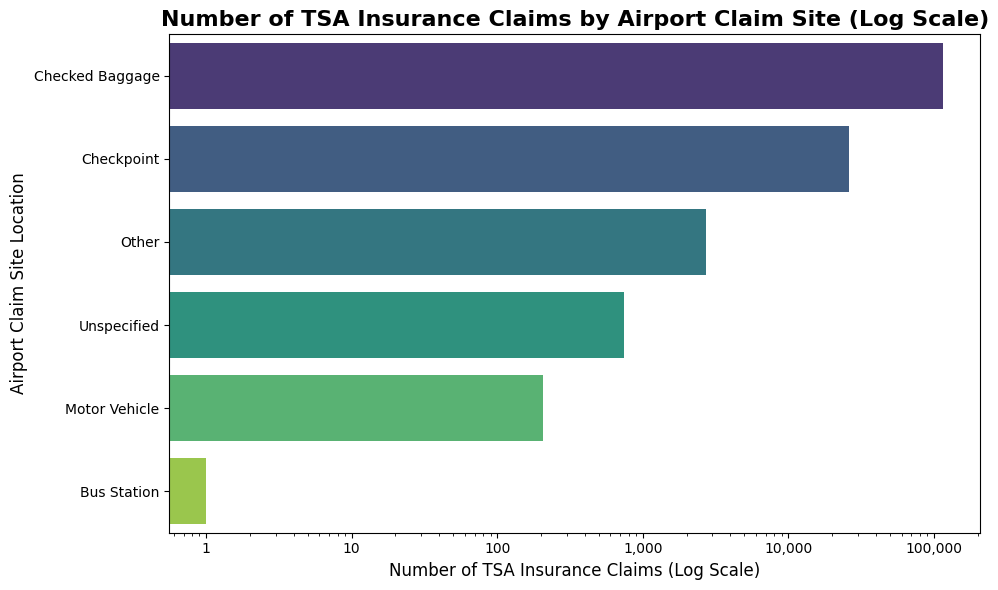

In [ ]:
import matplotlib.ticker as ticker

# Calculate total claims grouped by 'Claim Site'
claim_site_counts = tsa_claims['Claim Site'].value_counts()

# Set the visualization style
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=claim_site_counts.values, y=claim_site_counts.index, palette='viridis', hue=claim_site_counts.index, legend=False)

# Apply logarithmic scale to the x-axis
plt.xscale('log')

# Format the x-axis ticks to show actual values instead of scientific notation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:,.0f}'.format(y)))

# Format the axis and labels
plt.title('Number of TSA Insurance Claims by Airport Claim Site (Log Scale)', fontsize=16, fontweight='bold')
plt.xlabel('Number of TSA Insurance Claims (Log Scale)', fontsize=12)
plt.ylabel('Airport Claim Site Location', fontsize=12)

# Adjust spacing and display the plot
plt.tight_layout()

# Save image as a PNG file using plt.savefig directly
plt.savefig('claim_types_by_site.png', bbox_inches='tight', dpi=300)
print("Visualization successfully saved as 'claim_types_by_site.png'")

plt.show()

###Question 2 Answer: Checked baggage site has the highest claims

###Question 3: What type of claim is most common at each claim site?

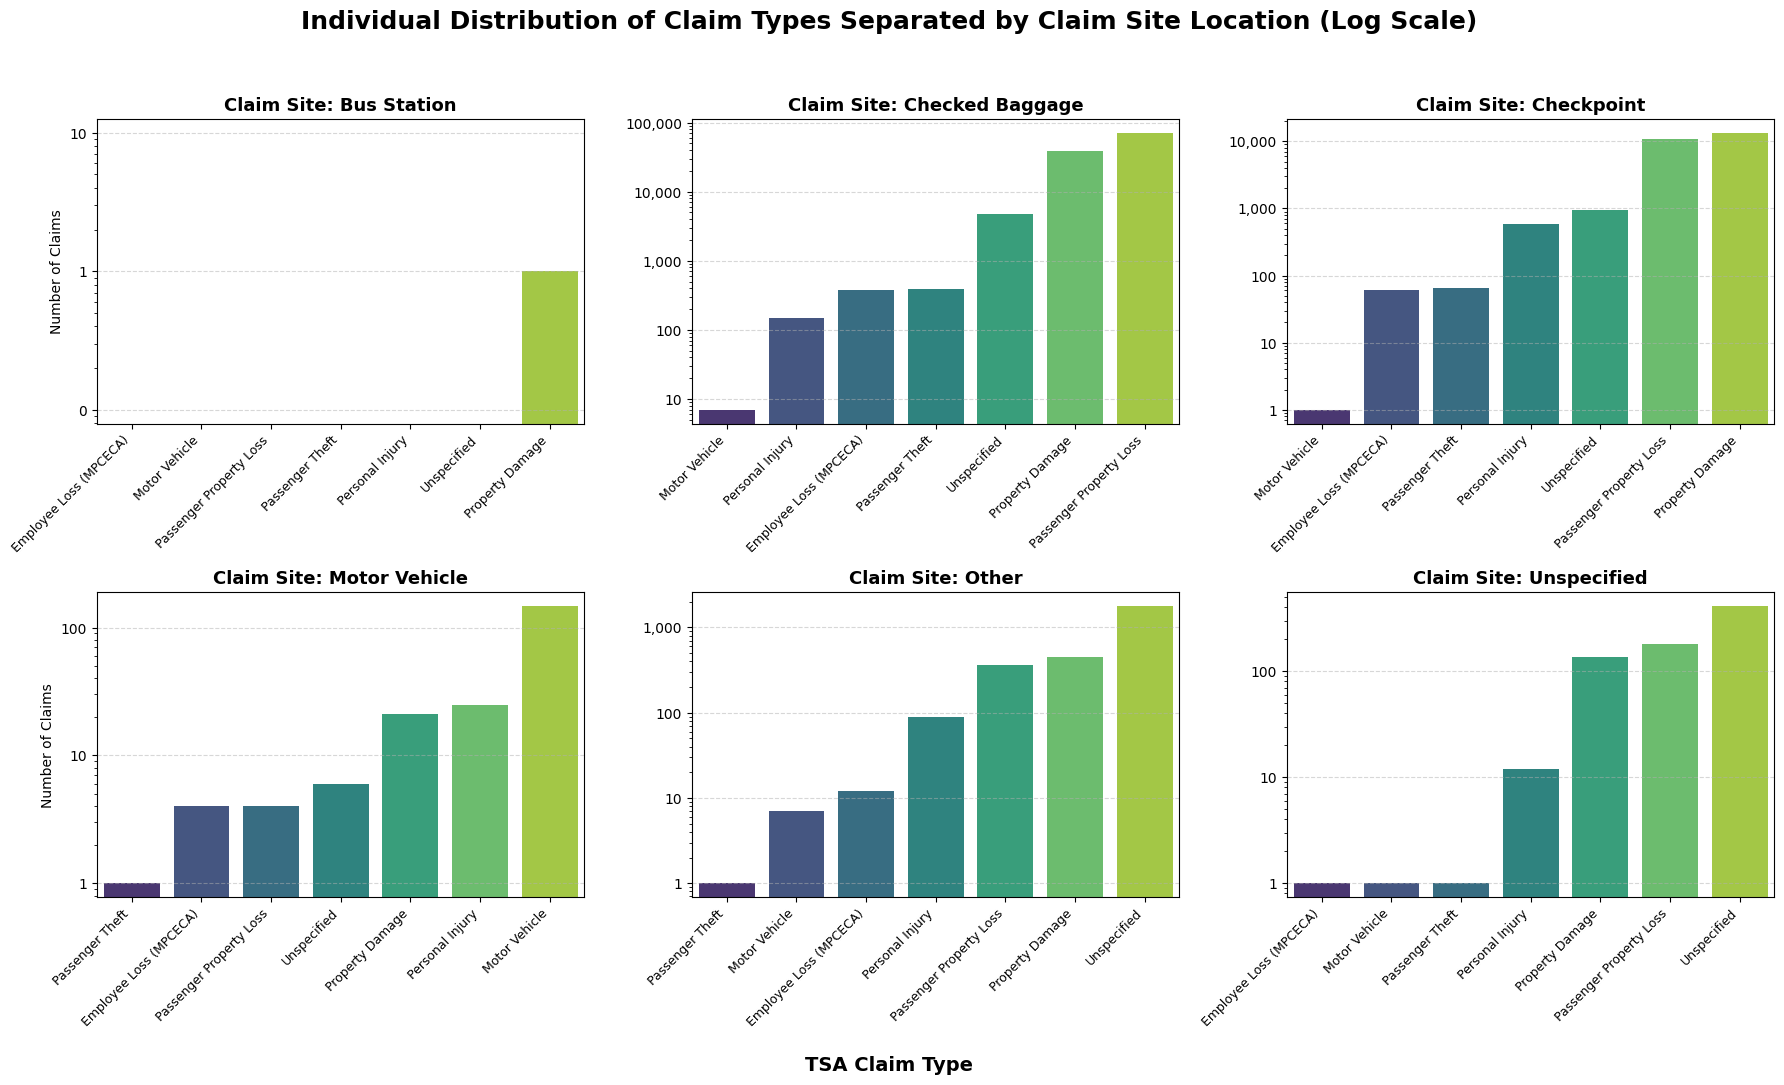

Visualization successfully saved as 'claim_types_by_claim_site.png'


In [ ]:
# Prepare and sort the data ascending by count within each site
site_type_counts = pd.crosstab(tsa_claims['Claim Site'], tsa_claims['Claim Type'])
chart_data = site_type_counts.reset_index().melt(id_vars='Claim Site', value_name='Number of Claims')
chart_data = chart_data.sort_values(by=['Claim Site', 'Number of Claims'], ascending=[True, True])

unique_sites = sorted(chart_data['Claim Site'].unique())
num_sites = len(unique_sites)

# Set up a grid of subplots (e.g., 2 rows x 3 columns for 6 sites)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11), sharex=False, sharey=False)
axes = axes.flatten()

for i, site in enumerate(unique_sites):
    ax = axes[i]
    site_subset = chart_data[chart_data['Claim Site'] == site]

    # Plot barplot
    sns.barplot(
        data=site_subset,
        x='Claim Type',
        y='Number of Claims',
        ax=ax,
        palette='viridis',
        hue='Claim Type',
        legend=False
    )

    # Customize individual subplot parameters
    ax.set_title(f'Claim Site: {site}', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Number of Claims' if i % 3 == 0 else '')

    # Set x-labels rotation
    ax.set_xticks(range(len(site_subset)))
    ax.set_xticklabels(site_subset['Claim Type'], rotation=45, ha='right', fontsize=9)

    # Apply log scale for sites with wide distribution differences
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:,.0f}'.format(y)))
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Hide any unused subplots (if any)
for j in range(num_sites, len(axes)):
    fig.delaxes(axes[j])

# Centered global label and title
fig.text(0.5, 0.02, 'TSA Claim Type', ha='center', va='center', fontsize=14, fontweight='bold')
fig.suptitle('Individual Distribution of Claim Types Separated by Claim Site Location (Log Scale)', fontsize=18, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

# Save the last active figure (the faceted subplots of claim types by site) as a PNG file
fig.savefig('claim_types_by_claim_site.png', bbox_inches='tight', dpi=300)
print("Visualization successfully saved as 'claim_types_by_claim_site.png'")

###Question 3 Answer: Passenger property loss is the most common across all sites

###Question 4: What is the typical claim amount?

###Analyzing Claim Amounts for statistical integriry to be used for analysis

In [ ]:
# Get and display the unique values for the Claim Amount column
unique_claim_amounts = tsa_claims['Claim Amount'].unique()
print(f"Number of unique claim amounts: {len(unique_claim_amounts)}")
print("Sample of unique claim amounts:")
print(unique_claim_amounts[:50])

Number of unique claim amounts: 33121
Sample of unique claim amounts:
['$350.00 ' '$100.00 ' '$278.88 ' '$50.00 ' '$84.79 ' '$459.01 '
 '$106.52 ' '$75.00 ' '$2;270.09 ' '$4;457.29 ' '$79.95 ' '$43.49 '
 '$16.71 ' '$450.00 ' 'Unspecified' '$200.00 ' '$110;000.00 ' '$68.00 '
 '$600.00 ' '$160.00 ' '$380.00 ' '$354.93 ' '$21.44 ' '$40.00 '
 '$275.00 ' '$30.00 ' '$1;832.22 ' '$250.00 ' '$1;200.00 ' '$678.00 '
 '$428.21 ' '$176.59 ' '$1;000.00 ' '$45.00 ' '$175.00 ' '$1;500.00 '
 '$213.00 ' '$249.00 ' '$85.00 ' '$750.00 ' '$150.00 ' '$300.00 '
 '$299.98 ' '$250;000.00 ' '$50;000.00 ' '$26.00 ' '$20.00 ' '$65.00 '
 '$199.00 ' '$379.90 ']


###Noticed dollar amounts included a "$" and a ";" included in the amount. Removed unnecessary symbols and obtained statistics to identify possible outliers

In [ ]:
# Clean and convert the 'Claim Amount' column to a numeric data type
# 1. Clean up string representations
cleaned_amounts = tsa_claims['Claim Amount'].astype(str) \
    .str.replace('$', '', regex=False) \
    .str.replace(';', '', regex=False) \
    .str.strip()

# 2. Convert 'Unspecified' or any non-numeric strings to NaN, and cast to float
tsa_claims['Claim Amount Cleaned'] = pd.to_numeric(cleaned_amounts, errors='coerce')

# 3. Calculate and display typical claim amount statistics
typical_median = tsa_claims['Claim Amount Cleaned'].median()
typical_mean = tsa_claims['Claim Amount Cleaned'].mean()
typical_min = tsa_claims['Claim Amount Cleaned'].min()
typical_max = tsa_claims['Claim Amount Cleaned'].max()

print(f"Typical (Median) Claim Amount: ${typical_median:,.2f}")
print(f"Average (Mean) Claim Amount: ${typical_mean:,.2f}")
print(f"Minimum Cleaned Claim Amount: ${typical_min:,.2f}")
print(f"Maximum Cleaned Claim Amount: ${typical_max:,.2f}")

Typical (Median) Claim Amount: $175.00
Average (Mean) Claim Amount: $21,313,862.88
Minimum Cleaned Claim Amount: $0.00
Maximum Cleaned Claim Amount: $3,000,000,000,000.00


In [ ]:
# Calculate quartile bounds for statistical outliers
Q1 = tsa_claims['Claim Amount Cleaned'].quantile(0.25)
Q3 = tsa_claims['Claim Amount Cleaned'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = tsa_claims[(tsa_claims['Claim Amount Cleaned'] < lower_bound) | (tsa_claims['Claim Amount Cleaned'] > upper_bound)]

print(f"Q1 (25th percentile): ${Q1:,.2f}")
print(f"Q3 (75th percentile): ${Q3:,.2f}")
print(f"IQR: ${IQR:,.2f}")
print(f"Statistical Outlier Threshold: Below ${lower_bound:,.2f} or Above ${upper_bound:,.2f}\n")

print(f"Number of statistical outliers: {len(outliers)} ({len(outliers) / len(tsa_claims) * 100:.2f}% of total claims)")
print("Descriptive statistics of outliers:")
display(outliers['Claim Amount Cleaned'].describe())

Q1 (25th percentile): $62.33
Q3 (75th percentile): $451.93
IQR: $389.60
Statistical Outlier Threshold: Below $-522.07 or Above $1,036.33

Number of statistical outliers: 17146 (11.77% of total claims)
Descriptive statistics of outliers:


,Claim Amount Cleaned
count,1.714600e+04
mean,1.759938e+08
std,2.291085e+10
min,1.036330e+03
25%,1.430000e+03
50%,2.000000e+03
75%,3.193412e+03
max,3.000000e+12


###Create histplot to showcase the entire distribution of claim amounts. Due to the distribution of the payouts tailing well off to the right for example, one instance that included a $3T payout, included statistics to hightlight avearge mean based on totals that both included and excluded outliers for context.

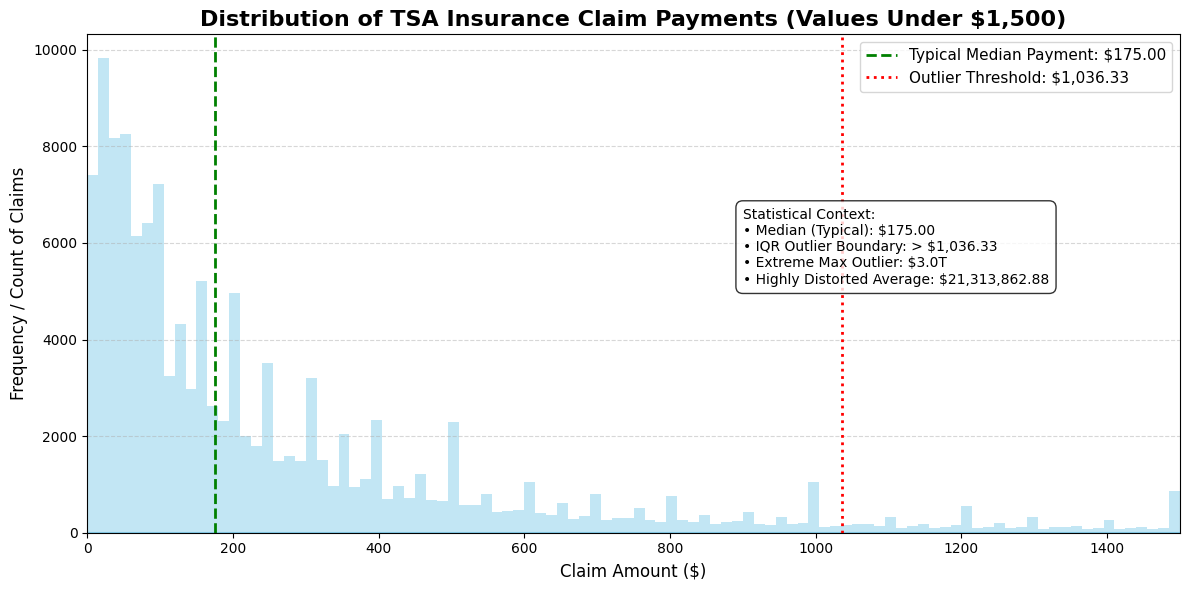

Visualization successfully saved as 'average_claim_payout.png'


In [ ]:
# Filter out NaN values for plotting
valid_claims = tsa_claims['Claim Amount Cleaned'].dropna()

# Create the visualization focusing on the typical range (under $1,500) to preserve detail
plt.figure(figsize=(12, 6))
sns.histplot(valid_claims, bins=100, binrange=(0, 1500), kde=True, color='skyblue', edgecolor='black')

# Add statistical marker lines
plt.axvline(typical_median, color='green', linestyle='--', linewidth=2, label=f'Typical Median Payment: ${typical_median:,.2f}')
plt.axvline(upper_bound, color='red', linestyle=':', linewidth=2, label=f'Outlier Threshold: ${upper_bound:,.2f}')

# Customize and dress the plot
plt.title('Distribution of TSA Insurance Claim Payments (Values Under $1,500)', fontsize=16, fontweight='bold')
plt.xlabel('Claim Amount ($)', fontsize=12)
plt.ylabel('Frequency / Count of Claims', fontsize=12)
plt.xlim(0, 1500)
plt.legend(fontsize=11, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add text explanation onto the plot
plt.text(900, plt.gca().get_ylim()[1]*0.5,
         f"Statistical Context:\n" \
         f"• Median (Typical): ${typical_median:,.2f}\n" \
         f"• IQR Outlier Boundary: > ${upper_bound:,.2f}\n" \
         f"• Extreme Max Outlier: $3.0T\n" \
         f"• Highly Distorted Average: ${typical_mean:,.2f}",
         bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'),
         fontsize=10)

plt.tight_layout()
plt.show()

# Save the last active figure (average insurance claim amount) as a PNG file
fig.savefig('average_claim_payout.png', bbox_inches='tight', dpi=300)
print("Visualization successfully saved as 'average_claim_payout.png'")

###Question 4 Answer: The median claim amount is $115.00

###Question 5: What is the overall claim approval rate:

###Determine what values reside within the "Status" feature

In [ ]:
# Calculate value counts for the 'Status' column representing approval status
tsa_claims['Status'].value_counts()

,count
Status,
Denied,68339
Approved,34999
Settled,27958
Canceled,7018
Insufficient; one of the following items required: sum certain; statement of fact; signature; location of incident; and date.,5381
Closed as a contractor claim,1315
Deny,367
In litigation,108
Approve in Full,69


###For analysis, changed all "-" to "Unspecified" for consistentcy and also shortened the instance description of "Insufficient...etc" to "Insufficient: Missing Information" as that closely aligns with the context of the elongated description entails.  

In [ ]:
# Clean and standardize 'Status' column labels
if hasattr(tsa_claims['Status'], 'cat'):
    # Add new category values if they do not exist
    for new_cat in ['Unspecified', 'Incomple: Missing Information']:
        if new_cat not in tsa_claims['Status'].cat.categories:
            tsa_claims['Status'] = tsa_claims['Status'].cat.add_categories([new_cat])

# Replace '-' with 'Unspecified'
tsa_claims['Status'] = tsa_claims['Status'].replace('-', 'Unspecified')

# Identify the full target 'Insufficient' string using string matching
target_insufficient_prefix = "Insufficient; one of the following items required"
match_mask = tsa_claims['Status'].astype(str).str.startswith(target_insufficient_prefix)

# Replace matching instances with 'Incomple: Missing Information'
tsa_claims.loc[match_mask, 'Status'] = 'Incomple:Missing Information'

# Clean up any unused categories if categorical
if hasattr(tsa_claims['Status'], 'cat'):
    tsa_claims['Status'] = tsa_claims['Status'].cat.remove_unused_categories()

# Verify updated value counts
print("Updated Status Value Counts:")
print(tsa_claims['Status'].value_counts())

Updated Status Value Counts:
Status
Denied                                               68339
Approved                                             34999
Settled                                              27958
Canceled                                              7018
Incomple:Missing Information                          5381
Closed as a contractor claim                          1315
Deny                                                   367
In litigation                                          108
Unspecified                                             70
Approve in Full                                         69
Settle                                                  39
Claim entered                                           14
In review                                                9
Claim has been assigned for further investigation        1
Pending response from claimant                           1
Name: count, dtype: int64


###Noticed two related instances, "Settle" and "Settled" but for integrity of the analysis, did not combine them both together as "Settle" may be in the process of being settled and "Settled" have acutally been completed settlement pay outs which would be labeled separately for a reason.

###Lollipop chart below to see the distribution of approval statuses as compared to the other resolutions

Square root lollipop chart successfully saved as 'claim_status_lollipop_sqrt_chart.png'


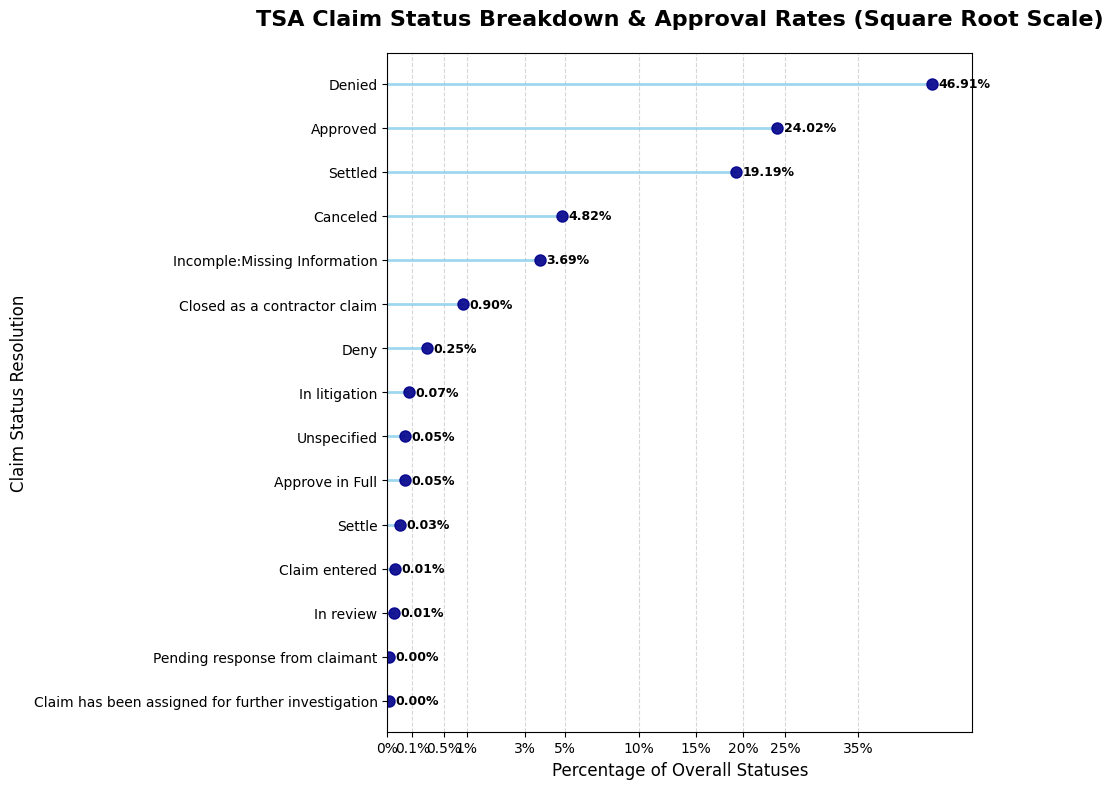

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Calculate counts and percentages
status_counts = tsa_claims['Status'].value_counts()
status_percentages = (status_counts / len(tsa_claims)) * 100

# Create a DataFrame
status_df = status_percentages.reset_index()
status_df.columns = ['Status', 'Percentage']
status_df = status_df.sort_values(by='Percentage', ascending=True)

# Apply square root transformation
status_df['Sqrt_Percentage'] = np.sqrt(status_df['Percentage'])

# Generate lollipop chart
plt.figure(figsize=(10, 8))

# Draw the horizontal lines using Sqrt values
plt.hlines(y=status_df['Status'], xmin=0, xmax=status_df['Sqrt_Percentage'], color='skyblue', alpha=0.8, linewidth=2)

# Draw the data points
plt.plot(status_df['Sqrt_Percentage'], status_df['Status'], "o", color='darkblue', markersize=8, alpha=0.9)

# Customize graph aesthetics
plt.title('TSA Claim Status Breakdown & Approval Rates (Square Root Scale)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Percentage of Overall Statuses', fontsize=12)
plt.ylabel('Claim Status Resolution', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Display actual percentages next to markers, positioned by their square root coordinate
for index, row in status_df.iterrows():
    plt.text(row['Sqrt_Percentage'] + 0.08, row['Status'], f"{row['Percentage']:.2f}%", va='center', fontsize=9, fontweight='bold')

# Create meaningful ticks mapping square roots back to original readable percentages
tick_percentages = [0, 0.1, 0.5, 1, 3, 5, 10, 15, 20, 25, 35]
plt.xticks(np.sqrt(tick_percentages), [f"{val}%" for val in tick_percentages])

plt.xlim(0, max(status_df['Sqrt_Percentage']) + 0.5)
plt.tight_layout()

# Save the plot
plt.savefig('claim_status_lollipop_sqrt_chart.png', bbox_inches='tight', dpi=300)
print("Square root lollipop chart successfully saved as 'claim_status_lollipop_sqrt_chart.png'")

plt.show()

###Question 5 Answer: The overall claim approval rate is 17.13%

###Question 6: What percent of the claim amount is paid for approved or settled claims?

###Filtered just instances "settled" and "approved" and included only instances that have an amount paid over $0.00 then compiled the overall percentage for both.

In [ ]:
import pandas as pd

# Define the statuses that fall under approved or settled claims
target_statuses = ['Approved','Settled',]

# Filter the dataframe for these statuses
approved_settled_df = tsa_claims[tsa_claims['Status'].isin(target_statuses)].copy()

# Create a boolean column representing if the claim was paid out (Claim Amount Cleaned > 0.00)
approved_settled_df['Paid Out'] = approved_settled_df['Claim Amount Cleaned'] > 0.00

# Group by status to calculate totals, paid count, and the percentage paid out
results = approved_settled_df.groupby('Status').agg(
    Total_Claims=('Claim Number', 'count'),
    Paid_Claims=('Paid Out', 'sum')
).reset_index()

results['Percent Paid Out (%)'] = (results['Paid_Claims'] / results['Total_Claims']) * 100

# Also calculate the overall aggregate metrics
overall_total = len(approved_settled_df)
overall_paid = approved_settled_df['Paid Out'].sum()
overall_pct = (overall_paid / overall_total) * 100

print("=== Breakdown by Status ===")
print(results.to_string(index=False, formatters={
    'Total_Claims': '{:,.0f}'.format,
    'Paid_Claims': '{:,.0f}'.format,
    'Percent Paid Out (%)': '{:.2f}%'.format
}))

=== Breakdown by Status ===
  Status Total_Claims Paid_Claims Percent Paid Out (%)
Approved       34,999      34,780               99.37%
 Settled       27,958      27,737               99.21%


###Create visual plot of TSA payout claims for instances of both approved and settled

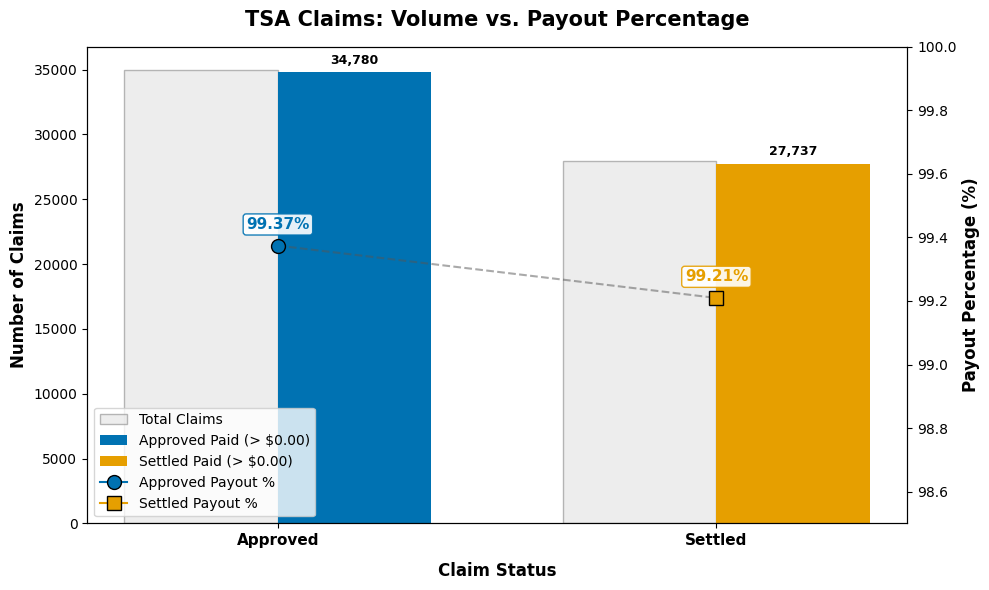

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Colorblind-friendly colors
color_approved = '#0072B2'  # Blue
color_settled = '#E69F00'   # Orange
color_bg_total = '#E6E6E6'   # Light grey for total claims volume reference

# Prepare data from previous calculation step
categories = results['Status'].tolist()  # ['Approved', 'Settled']
total_claims = results['Total_Claims'].tolist()
paid_claims = results['Paid_Claims'].tolist()
percent_paid = results['Percent Paid Out (%)'].tolist()

x = np.arange(len(categories))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Left Y-axis: Volumes of Claims (Total vs Paid)
# We'll display Total Claims as light grey background bars and Paid Claims in status-specific colorblind colors
rects_total = ax1.bar(x - width/2, total_claims, width, label='Total Claims', color=color_bg_total, edgecolor='#999999', alpha=0.7)

# Draw separate colored bars for each status to ensure distinct colorblind colors
rect_app = ax1.bar(x[0] + width/2, paid_claims[0], width, label='Approved Paid (> $0.00)', color=color_approved)
rect_set = ax1.bar(x[1] + width/2, paid_claims[1], width, label='Settled Paid (> $0.00)', color=color_settled)

ax1.set_xlabel('Claim Status', fontsize=12, fontweight='bold', labelpad=10)
ax1.set_ylabel('Number of Claims', color='black', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax1.set_title('TSA Claims: Volume vs. Payout Percentage', fontsize=15, fontweight='bold', pad=15)

#Right Y-axis: Payout Percentages
ax2 = ax1.twinx()
# Plot separate lines or marker segments to match the status colors
ax2.plot(x[0], percent_paid[0], marker='o', color=color_approved, markersize=10, markeredgecolor='black', label='Approved Payout %')
ax2.plot(x[1], percent_paid[1], marker='s', color=color_settled, markersize=10, markeredgecolor='black', label='Settled Payout %')

#Draw a light dashed connector line between both status percentages
ax2.plot(x, percent_paid, color='#555555', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)

ax2.set_ylabel('Payout Percentage (%)', color='black', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='black')
ax2.set_ylim(98.5, 100.0)  # Focused range to highlight high payout rates

# Direct Annotations for Volumes on Bars
for bar, count in zip([rect_app, rect_set], paid_claims):
    for patch in bar:
        height = patch.get_height()
        ax1.annotate(f'{height:,}',
                     xy=(patch.get_x() + patch.get_width() / 2, height),
                     xytext=(0, 4),  # 4 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

# Direct Annotations for Percentages
for i, val in enumerate(percent_paid):
    text_color = color_approved if i == 0 else color_settled
    ax2.annotate(f'{val:.2f}%',
                 xy=(i, val),
                 xytext=(0, 12),
                 textcoords="offset points",
                 ha='center', color=text_color, fontweight='bold', fontsize=11,
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor=text_color, alpha=0.9))

# Create unified legend
handles_ax1, labels_ax1 = ax1.get_legend_handles_labels()
handles_ax2, labels_ax2 = ax2.get_legend_handles_labels()
ax1.legend(handles_ax1 + handles_ax2, labels_ax1 + labels_ax2, loc='lower left', fontsize=10, frameon=True)

plt.tight_layout()
plt.savefig('payout_volumes_and_percentages.png', dpi=300, bbox_inches='tight')
plt.show()

###Question 6 Answer: The percentage of approved claims paid is 99.37% and the percentage of settled claims paid is 99.21%

###Question 7: What are the five airports with the most claims?

###Determine the top five named airports with the hiest amounts of claims

In [ ]:
# Filter out 'Unspecified' entries from TSA claims dataset
valid_claims = tsa_claims[tsa_claims['Airport Name'] != 'Unspecified']

# Get the value counts of the top 5 airports
top_5_airports = valid_claims['Airport Name'].value_counts().head(5)

print("Top 5 Airports with the Most TSA Claims:")
for rank, (name, count) in enumerate(top_5_airports.items(), 1):
    print(f"{rank}. {name}: {count:,} claims")

Top 5 Airports with the Most TSA Claims:
1. NADI INTERNATIONAL: 8,522 claims
2. Los Angeles International Airport: 6,765 claims
3. John F. Kennedy International: 5,264 claims
4. Chicago O'Hare International Airport: 5,050 claims
5. Newark International Airport: 4,931 claims


###Create visualization of above top 5 airports by claim amounts

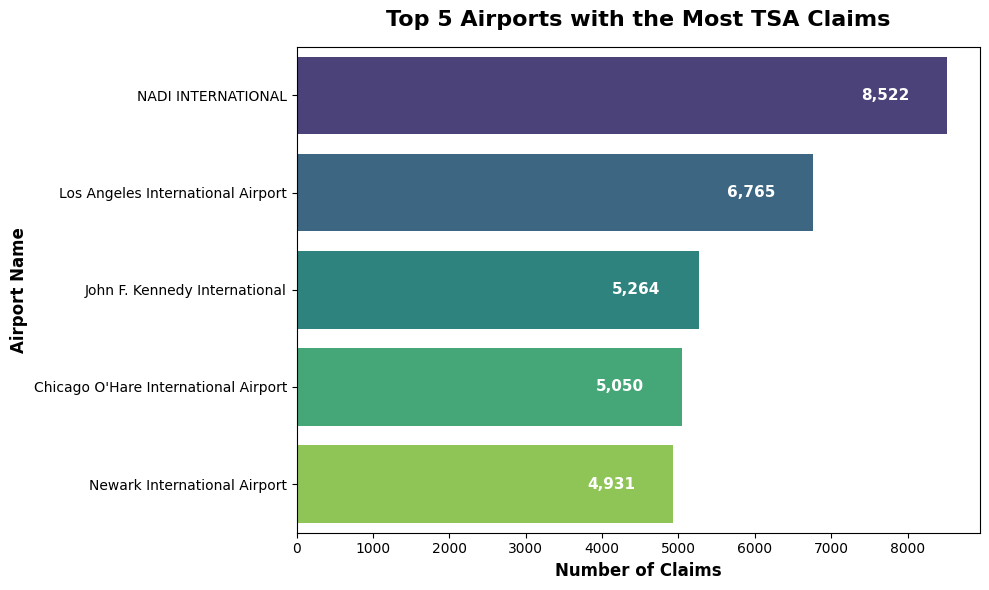

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve top_5_airports series if already in state, or rebuild it
if 'top_5_airports' not in globals():
    valid_claims = tsa_claims[tsa_claims['Airport Name'] != 'Unspecified']
    top_5_airports = valid_claims['Airport Name'].value_counts().head(5)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_5_airports.values,
    y=top_5_airports.index,
    palette='viridis',
    hue=top_5_airports.index,
    legend=False
)

# Style the graph
plt.title('Top 5 Airports with the Most TSA Claims', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Number of Claims', fontsize=12, fontweight='bold')
plt.ylabel('Airport Name', fontsize=12, fontweight='bold')

# Add numeric annotations to the ends of the bars
for index, value in enumerate(top_5_airports.values):
    plt.text(value - 500, index, f'{value:,}', va='center', ha='right', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('top_5_airports_claims.png', dpi=300, bbox_inches='tight')
plt.show()

###Changed above chart to logarithmic scale to better see the distribution of values

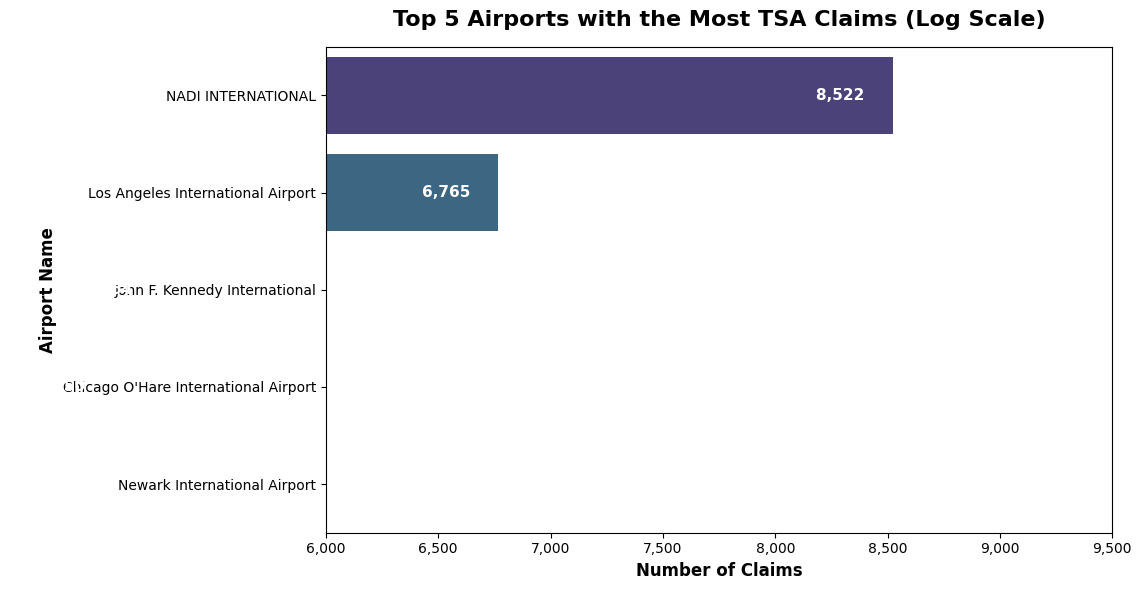

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve top_5_airports series if already in state, or rebuild it
if 'top_5_airports' not in globals():
    valid_claims = tsa_claims[tsa_claims['Airport Name'] != 'Unspecified']
    top_5_airports = valid_claims['Airport Name'].value_counts().head(5)

# Create horizontal bar chart
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=top_5_airports.values,
    y=top_5_airports.index,
    palette='viridis',
    hue=top_5_airports.index,
    legend=False
)

# Set x-axis limits and custom ticks from 6000 to 9500 with increments of 500
plt.xlim(6000, 9500)
custom_ticks = np.arange(6000, 9501, 500)
ax.set_xticks(custom_ticks)

# Format the x-axis labels with thousands separator
ax.set_xticklabels([f'{val:,}' for val in custom_ticks])

# Style the graph
plt.title('Top 5 Airports with the Most TSA Claims (Log Scale)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Number of Claims', fontsize=12, fontweight='bold')
plt.ylabel('Airport Name', fontsize=12, fontweight='bold')

# Add numeric annotations to the ends of the bars
for index, value in enumerate(top_5_airports.values):
    plt.text(value - 100, index, f'{value:,} ', va='center', ha='right', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('top_5_airports_claims_custom_scale.png', dpi=300, bbox_inches='tight')
plt.show()

###Question 7 Answer: John F Kennedy International Airport has the highest claims

###Question 8: Has the total close amount increased or decreased over time?

###Determine trend of close amount via line graph with downsized scale to more accurately identify trends from year to year across timeframe

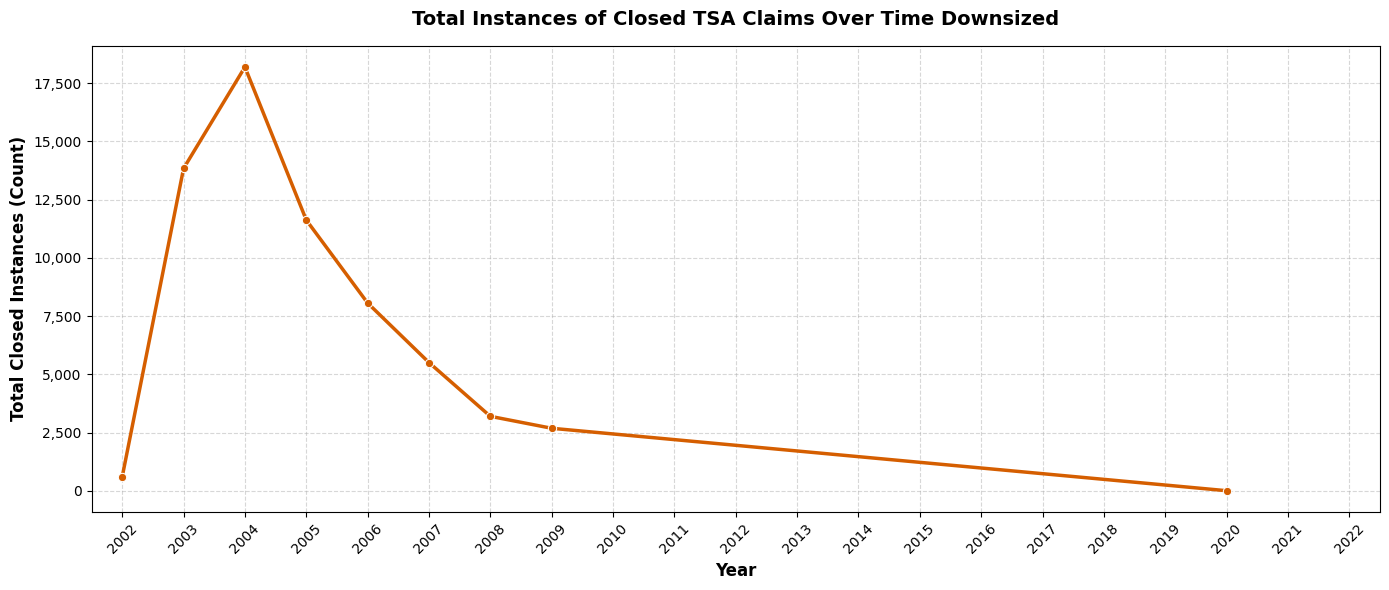

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

#Verified 'Unspecified' or missing values filtered out
valid_claims = tsa_claims[
    (tsa_claims['Close Amount'] != 'Unspecified') &
    (tsa_claims['Date Received'] != 'Unspecified')
].copy()

#Convert Date Received to datetime and drop invalid dates
valid_claims['Date Received'] = pd.to_datetime(valid_claims['Date Received'], errors='coerce')
valid_claims = valid_claims.dropna(subset=['Date Received'])

#Clean numeric Close Amount values and filter out $0.0
valid_claims['Close Amount Cleaned'] = valid_claims['Close Amount'].astype(str) \
    .str.replace('$', '', regex=False) \
    .str.replace(';', '', regex=False) \
    .str.strip()
valid_claims['Close Amount Cleaned'] = pd.to_numeric(valid_claims['Close Amount Cleaned'], errors='coerce')
valid_claims = valid_claims.dropna(subset=['Close Amount Cleaned'])
valid_claims = valid_claims[valid_claims['Close Amount Cleaned'] > 0.0]

#Limit data to start in starting and ending years
valid_claims = valid_claims[(valid_claims['Date Received'].dt.year >= 2002) & (valid_claims['Date Received'].dt.year <= 2022)]

#Downsize data: Group by Year and count the number of closed instances
time_trends_instances = valid_claims.groupby(valid_claims['Date Received'].dt.year).agg(
    Closed_Instances_Count=('Close Amount Cleaned', 'count')
).reset_index()
time_trends_instances.columns = ['Year', 'Closed_Instances_Count']

#Create lineplot
plt.figure(figsize=(14, 6))
sns.lineplot(data=time_trends_instances, x='Year', y='Closed_Instances_Count', color='#D55E00', linewidth=2.5, marker='o')

#Customize x-axis to show ticks for every single year from 2002 to 2022
years = list(range(2002, 2023))
plt.xticks(years, [str(yr) for yr in years], rotation=45)
plt.xlim(2001.5, 2022.5)

# Title and Label Styling
plt.title('Total Instances of Closed TSA Claims Over Time Downsized', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Total Closed Instances (Count)', fontsize=12, fontweight='bold')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('closed_instances_yearly_ticks.png', dpi=300, bbox_inches='tight')
plt.show()

###Question 8 Answer: the close amounts peaked in 2004 and have been drastically through the end of the timeline. Notice no instances from 2009 through 2020 which may explain number of unspecified or missing dates.  

##Part 3 Geographic Visualizations (Geopandas)

###Create geopandas map of US airpot locations

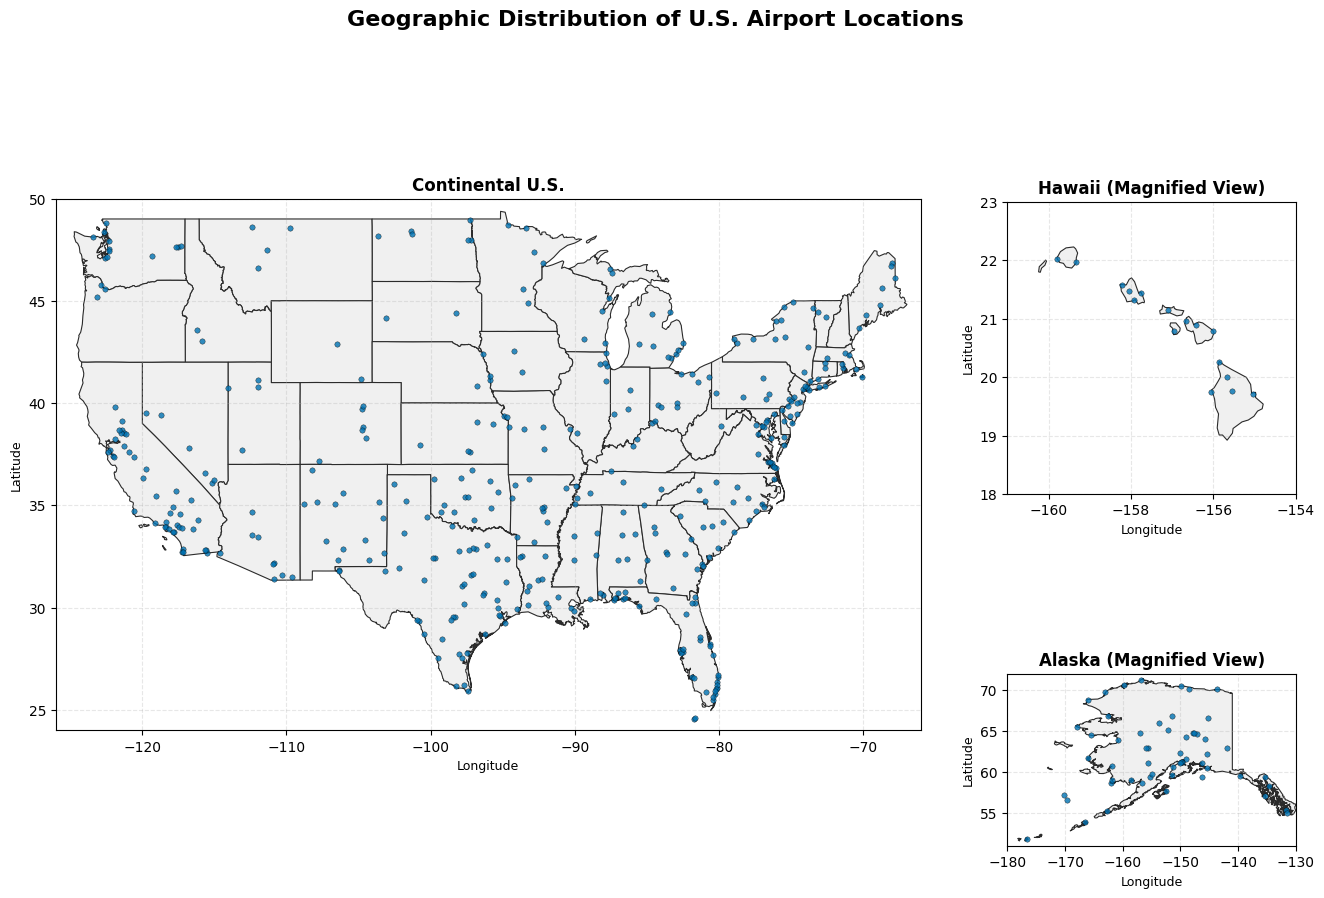

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.gridspec as gridspec

# Re-create the U.S. helper indicator column in airport_data if it got lost
is_us = airport_data['Country'].astype(str).str.upper().isin(['USA', 'UNITED STATES', 'UNITED STATES OF AMERICA'])
airport_data['U.S.'] = is_us

#Filter airport_data for U.S. airports with valid coordinates
us_airports = airport_data[
    (airport_data['U.S.'] == True) &
    (airport_data['LatitudeDecimalDegrees'] != 0.0) &
    (airport_data['LongitudeDecimalDegrees'] != 0.0)
].copy()

#Create the GeoDataFrame for airport locations
geometry = [Point(xy) for xy in zip(us_airports['LongitudeDecimalDegrees'], us_airports['LatitudeDecimalDegrees'])]
airports_gdf = gpd.GeoDataFrame(us_airports, geometry=geometry, crs="EPSG:4326")

#Align Coordinate Reference Systems
if states_map.crs is None:
    states_map.crs = "EPSG:4326"
else:
    airports_gdf = airports_gdf.to_crs(states_map.crs)

#Set up the figure layout with gridspec to match the previous multi-view
fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 2, width_ratios=[3, 1], height_ratios=[3, 1], hspace=0.15, wspace=0.15)

#Setup axes
ax_main = fig.add_subplot(gs[:, 0])
ax_hi = fig.add_subplot(gs[0, 1])
ax_ak = fig.add_subplot(gs[1, 1])

#Helper function to plot base maps and locations uniformly
def plot_airport_locations(ax, xlim, ylim, title):
    # Plot states polygon background
    states_map.plot(ax=ax, color='#F0F0F0', edgecolor='#2B2B2B', linewidth=0.8)

    # Plot uniform airport locations (constant size and color)
    ax.scatter(
        airports_gdf.geometry.x,
        airports_gdf.geometry.y,
        s=15,
        color='#0072B2',
        alpha=0.8,
        edgecolor='black',
        linewidth=0.3,
        zorder=3
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)

#Plot the three views
plot_airport_locations(ax_main, (-126, -66), (24, 50), "Continental U.S.")
plot_airport_locations(ax_hi, (-161, -154), (18, 23), "Hawaii (Magnified View)")
plot_airport_locations(ax_ak, (-180, -130), (51, 72), "Alaska (Magnified View)")

#Standardize labels and ticks
for ax in [ax_main, ax_hi, ax_ak]:
    ax.set_xlabel('Longitude', fontsize=9)
    ax.set_ylabel('Latitude', fontsize=9)

#Global Title
fig.suptitle('Geographic Distribution of U.S. Airport Locations', fontsize=16, fontweight='bold', y=0.95)

plt.savefig('us_airports_locations_multi_view.png', dpi=300, bbox_inches='tight')
plt.show()

###Create Geopandas map that scales the markers for the airports based on total amount claims

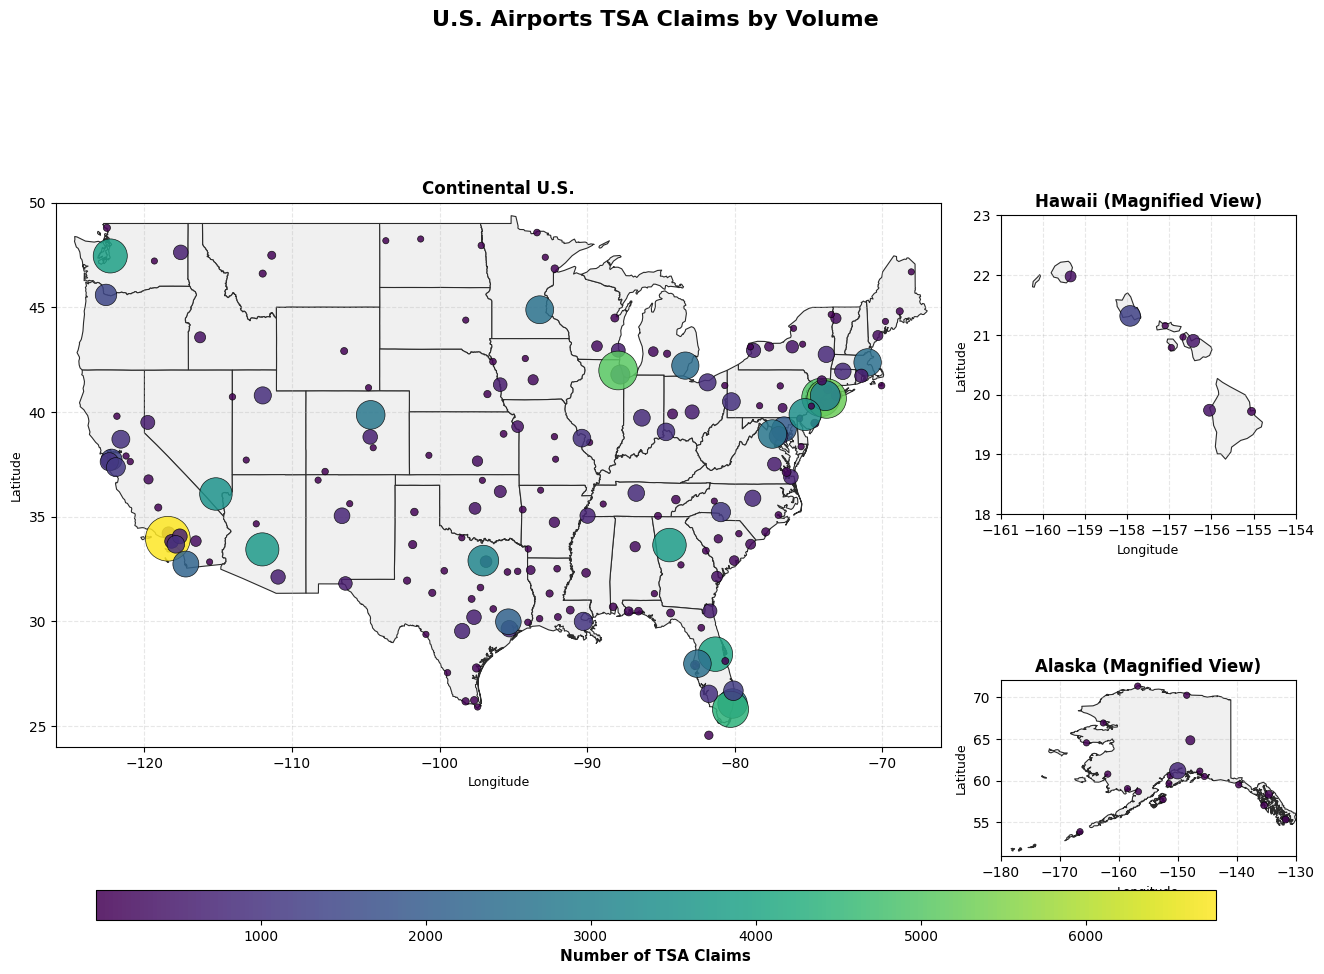

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
import matplotlib.gridspec as gridspec

#Calculate the total number of claims per airport
claims_per_airport = tsa_claims[
    (tsa_claims['Airport Code'] != 'Unspecified') &
    (tsa_claims['Airport Code'] != '-')
]['Airport Code'].value_counts().reset_index()
claims_per_airport.columns = ['IATACode', 'Claims_Count']

#Filter airport_data for U.S. airports with valid coordinates
us_airports = airport_data[
    (airport_data['U.S.'] == True) &
    (airport_data['LatitudeDecimalDegrees'] != 0.0) &
    (airport_data['LongitudeDecimalDegrees'] != 0.0)
].copy()

#Merge airport coordinates with claims frequency
us_airports_claims = pd.merge(us_airports, claims_per_airport, on='IATACode', how='inner')

#Create the GeoDataFrame
geometry = [Point(xy) for xy in zip(us_airports_claims['LongitudeDecimalDegrees'], us_airports_claims['LatitudeDecimalDegrees'])]
airports_claims_gdf = gpd.GeoDataFrame(us_airports_claims, geometry=geometry, crs="EPSG:4326")

# Align Coordinate Reference Systems
if states_map.crs is None:
    states_map.crs = "EPSG:4326"
else:
    airports_claims_gdf = airports_claims_gdf.to_crs(states_map.crs)

#Set up the figure layout with gridspec to allow custom sizing
fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 2, width_ratios=[3, 1], height_ratios=[3, 1], hspace=0.1, wspace=0.1)

# Adjustements for figure placements:

# Main axis for Continental US (takes up the left column)
ax_main = fig.add_subplot(gs[:, 0])
# Smaller axis specifically for Hawaii (placed in the top right)
ax_hi = fig.add_subplot(gs[0, 1])
# Smaller axis specifically for Alaska (placed in the bottom right for completeness)
ax_ak = fig.add_subplot(gs[1, 1])

min_marker_size = 20
scaling_factor = 0.15
marker_sizes = min_marker_size + (airports_claims_gdf['Claims_Count'] * scaling_factor)

# Helper function to plot base maps and points consistently on each subplot
def plot_submap(ax, xlim, ylim, title):
    states_map.plot(ax=ax, color='#F0F0F0', edgecolor='#2B2B2B', linewidth=0.8)

    scatter = ax.scatter(
        airports_claims_gdf.geometry.x,
        airports_claims_gdf.geometry.y,
        s=marker_sizes,
        c=airports_claims_gdf['Claims_Count'],
        cmap='viridis',
        alpha=0.85,
        edgecolor='black',
        linewidth=0.5,
        zorder=3
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    return scatter

# Plot Continental US
scatter_main = plot_submap(ax_main, (-126, -66), (24, 50), "Continental U.S.")

# Plot Hawaii zoomed in
plot_submap(ax_hi, (-161, -154), (18, 23), "Hawaii (Magnified View)")

# Plot Alaska zoomed in
plot_submap(ax_ak, (-180, -130), (51, 72), "Alaska (Magnified View)")

# Adjust ticks and labels for cleaner aesthetic
for ax in [ax_main, ax_hi, ax_ak]:
    ax.set_xlabel('Longitude', fontsize=9)
    ax.set_ylabel('Latitude', fontsize=9)

# Global title and unified colorbar at the bottom
fig.suptitle('U.S. Airports TSA Claims by Volume', fontsize=16, fontweight='bold', y=0.96)

cbar_ax = fig.add_axes([0.15, 0.05, 0.7, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(scatter_main, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Number of TSA Claims', fontsize=11, fontweight='bold')

plt.savefig('us_airports_claims_multi_view.png', dpi=300, bbox_inches='tight')
plt.show()


References:
https://pilotinstitute.com/airport-codes-explained/